Using Simulated Annealing solver...

[SA Iter 0] objective = 4250.0
Permutation matrix:
[[1. 0. 0. 0.]
 [0. 0. 0. 1.]
 [0. 0. 1. 0.]
 [0. 1. 0. 0.]]


[SA Iter 1] objective = 3850.0
Permutation matrix:
[[0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]
 [1. 0. 0. 0.]]



Problem: ../data/Qaplib/chr4a, n: 4
Degrees: [9 9 9 9 9 9 9 9 9 9 9 9 9 9 9 9]
Max degree = 9, index = 0
Q shape=(16, 16), A shape=(4, 4), B shape=(4, 4)



[SA Iter 2] objective = 3850.0
Permutation matrix:
[[0. 0. 1. 0.]
 [0. 1. 0. 0.]
 [0. 0. 0. 1.]
 [1. 0. 0. 0.]]




QuCOOP: [2 1 3 0], objective=3850.0
Ground truth: [2 1 3 0], objective=3850.0


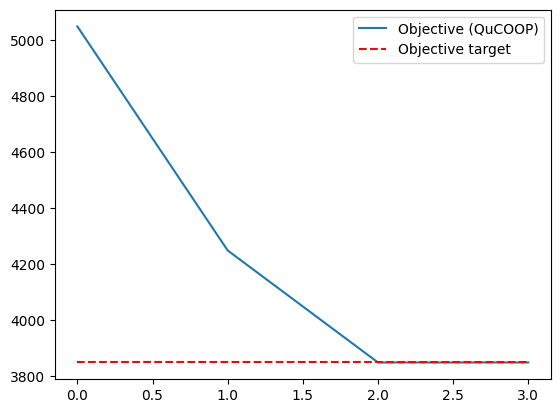

In [1]:
import sys
import os
import re
import logging

import numpy as np
import matplotlib.pyplot as plt

# -----------------
# Import local modules
# -----------------
current_dir = os.getcwd()
parent_dir = os.path.abspath(os.path.join(current_dir, ".."))
sys.path.insert(0, parent_dir)

import qap
import utils


if __name__ == "__main__":
    logging.basicConfig(level=logging.INFO, format="%(message)s")

    # =========================
    #  Load Problem Instance
    # =========================
    problem = "../data/Qaplib/chr4a"
    n = int(re.findall(r"\d+", problem)[0])
    print(f"Problem: {problem}, n: {n}")

    # Parse ground truth solution
    sol_star = np.loadtxt(problem + ".sln", skiprows=1).astype(np.int32)
    P_star = utils.permutation_idx2mat(sol_star - 1)

    # Parse cost matrices A and B
    data = np.loadtxt(problem + ".dat", skiprows=2)
    A = data[:n, :]
    B = data[n:, :]

    # Symmetrize if needed
    if np.array_equal(A.T, A) and not np.array_equal(B.T, B):
        B = 0.5 * (B + B.T)
    if not np.array_equal(A.T, A) and np.array_equal(B.T, B):
        A = 0.5 * (A + A.T)

    # Build Q matrix
    Q = np.kron(A, B)
    Q = 0.5 * (Q + Q.T)

    # Diagnostics
    degrees = np.count_nonzero(Q, axis=1)
    max_degree = np.max(degrees)
    max_vertex = np.argmax(degrees)
    print(f"Degrees: {degrees}")
    print(f"Max degree = {max_degree}, index = {max_vertex}")

    # Add regularization
    alpha = np.min(np.linalg.eigvalsh(Q))

    # =========================
    #  Solve with our method
    # =========================
    solver = qap.QAP(Q, alpha, P_star)
    print(f"Q shape={Q.shape}, A shape={A.shape}, B shape={B.shape}")
    history = solver.solve(maxiter=50, layers=4, method="sa")  # 或 method="sa"

    # =========================
    #  Results
    # =========================
    print(
        f"\nQuCOOP: {(solver.P_sol @ np.arange(n)).astype(int)}, "
        f"objective={solver.objective(solver.P_sol)}"
        f"\nGround truth: {(P_star @ np.arange(n)).astype(int)}, "
        f"objective={solver.objective(P_star)}"
    )

    # Plot optimization history
    plt.plot(history, label="Objective (QuCOOP)")
    plt.hlines(solver.objective(P_star), 0, len(history) - 1,
               linestyles="--", color="r", label="Objective target")
    plt.legend()
    plt.show()

Iter 0, delta = [3.14159265], error_R = 3.56455844, error_P = 4.0, objective = 2.83287609
Iter 1, delta = [1.57079633], error_R = 3.4156288, error_P = 4.0, objective = 3.75615834
Iter 2, delta = [1.57079633], error_R = 2.80820557, error_P = 4.0, objective = 1.56062629
Iter 3, delta = [0.78539816], error_R = 2.00987006, error_P = 4.0, objective = 0.86401454
Iter 4, delta = [0.78539816], error_R = 2.31789647, error_P = 4.0, objective = 0.14938161
Iter 5, delta = [0.39269908], error_R = 1.83596664, error_P = 4.0, objective = 0.10938345
Iter 6, delta = [0.39269908], error_R = 2.21648823, error_P = 4.0, objective = 0.05376794
Iter 7, delta = [0.19634954], error_R = 1.84210225, error_P = 4.0, objective = 0.10961321
Iter 8, delta = [0.19634954], error_R = 1.97922752, error_P = 4.0, objective = 0.0038612
Iter 9, delta = [0.09817477], error_R = 2.06177485, error_P = 4.0, objective = 0.00679397
Iter 10, delta = [0.09817477], error_R = 1.96473867, error_P = 4.0, objective = 0.00319557
Iter 11, de

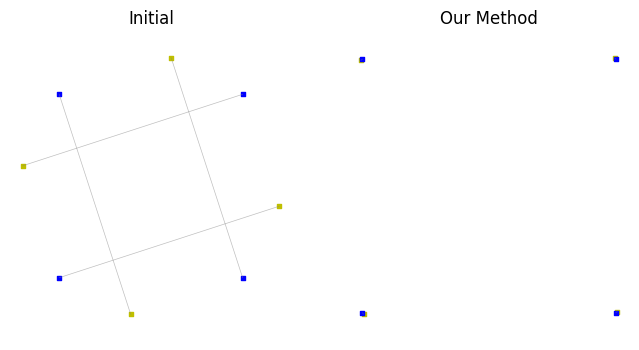

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
import psr, utils


if __name__ == "__main__":
    ref_color, tmp_color = "b", "y"

    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    size = 7

    # -------------------
    # Data preparation
    # -------------------
    ref_points = np.loadtxt("../data/square/square.dat", delimiter=",").T
    tmp_points = ref_points.copy()

    ref_points -= ref_points.mean(axis=1, keepdims=True)
    tmp_points -= tmp_points.mean(axis=1, keepdims=True)

    a, b = ref_points.shape[1], tmp_points.shape[1]
    n = max(a, b)

    ref_points = np.pad(ref_points, ((0, 0), (0, n - a)),
                        "constant", constant_values=0)
    tmp_points = np.pad(tmp_points, ((0, 0), (0, n - b)),
                        "constant", constant_values=0)

    # Apply random transform
    theta = np.deg2rad(np.random.randint(-80, 80))
    R = np.array([[np.cos(theta), -np.sin(theta)],
                  [np.sin(theta),  np.cos(theta)]])
    P = np.eye(n)
    np.random.shuffle(P)

    tmp_points = R @ tmp_points
    ref_points = ref_points @ P

    # Ground truth
    R_star, P_star = R.T, P.T

    # Random colors
    colors = [f"#{np.random.randint(0, 0xFFFFFF):06x}" for _ in range(n)]

    # -------------------
    # Our solver
    # -------------------
    alpha, beta = 0.1, 1.0
    solver = psr.PointSetRegistration(
        ref_points=ref_points,
        tmp_points=tmp_points,
        alpha=alpha, beta=beta,
        R_star=R_star, P_star=P_star
    )
    history = solver.solve(K=5, maxiter=15, method="sa", layers=20)

    R_rec, P_rec = solver.R_sol, solver.P_sol

    # -------------------
    # Plot: Initial
    # -------------------
    ref_init = ref_points @ np.eye(n)
    tmp_init = np.eye(2) @ tmp_points
    ref_init, tmp_init = ref_init[:, :a], tmp_init[:, :b]

    for i, c in zip(range(n), colors):
        try:
            ax[0].scatter(*tmp_init[:, i], color=tmp_color, marker='s', s=size)
            ax[0].scatter(*ref_init[:, i], color=ref_color, marker='s', s=size)
            ax[0].plot([ref_init[0, i], tmp_init[0, i]],
                       [ref_init[1, i], tmp_init[1, i]],
                       c="gray", linewidth=0.5, alpha=0.5)
        except Exception:
            ax[0].scatter(*ref_init[:, i], color=ref_color, marker='s', s=size)
    ax[0].set_title("Initial")
    ax[0].axis("equal")
    ax[0].axis(False)

    # -------------------
    # Plot: Our method
    # -------------------
    ref_final = ref_points @ P_rec
    tmp_final = R_rec @ tmp_points
    ref_final, tmp_final = ref_final[:, :a], tmp_final[:, :b]

    for i, c in zip(range(n), colors):
        try:
            ax[1].scatter(*tmp_final[:, i], color=tmp_color, marker='s', s=size)
            ax[1].scatter(*ref_final[:, i], color=ref_color, marker='s', s=size)
            ax[1].plot([ref_final[0, i], tmp_final[0, i]],
                       [ref_final[1, i], tmp_final[1, i]],
                       c="gray", linewidth=0.5, alpha=0.5)
        except Exception:
            ax[1].scatter(*ref_final[:, i], color=ref_color, marker='s', s=size)
    ax[1].set_title("Our Method")
    ax[1].axis("equal")
    ax[1].axis(False)

    plt.show()

COCO WARNING: coco_suite(): Some keys in suite instance were ignored:
 instance
Valid keys for suite instance are:
 year
 instances

COCO WARNING: coco_suite(): Some keys in suite instance were ignored:
 instance
Valid keys for suite instance are:
 year
 instances



[INFO] Testing BBOB problem: BBOB suite problem f1 instance 2 in 5D (Index: 1)
[TEST] Optimization Results on BBOB Problem
Problem Name: BBOB suite problem f1 instance 2 in 5D
Best Solution Found: [0 0 0 1 1]
Best Objective Value: 440.95251648000004
Objective Value History: [448.48211648, 440.95251648000004, 440.95251648000004, 440.95251648000004, 441.67091648, 441.67091648, 440.95251648000004, 440.95251648000004, 441.67091648, 441.67091648, 440.95251648000004, 440.95251648000004, 441.67091648, 441.67091648, 440.95251648000004, 440.95251648000004, 441.67091648, 441.67091648, 440.95251648000004, 440.95251648000004, 441.67091648, 441.67091648, 440.95251648000004, 440.95251648000004, 441.67091648, 441.67091648, 440.95251648000004, 440.95251648000004, 441.67091648, 441.67091648, 440.95251648000004, 440.95251648000004, 441.67091648, 441.67091648, 440.95251648000004, 440.95251648000004, 441.67091648, 441.67091648, 440.95251648000004, 440.95251648000004, 441.67091648, 441.67091648, 440.952516

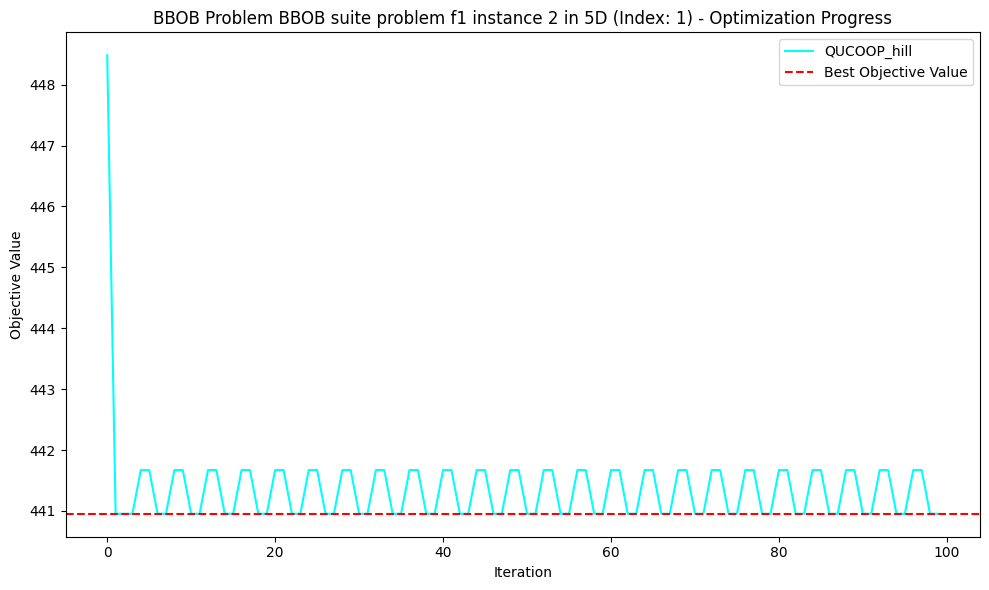

In [1]:
import cocoex  # COCO framework for BBOB problems
from BBOB_QUCOOP1_hill import QUCOOP_hill  # Import your QUCOOP_hill implementation

# ============================================================
# TEST CONFIGURATION
# ============================================================
DIMENSION = 5               # Dimensionality of the BBOB problems
MAX_ITER = 50               # Maximum number of iterations for QUCOOP_hill
SUITE_NAME = "bbob"         # Use the BBOB dataset
SUITE_INSTANCE = "instance:1"
SUITE_OPTIONS = f"dimensions:{DIMENSION}"

# ============================================================
# SETUP BBOB SUITE
# ============================================================
# Load the BBOB problem suite
suite = cocoex.Suite(SUITE_NAME, SUITE_INSTANCE, SUITE_OPTIONS)

# Select a BBOB problem (e.g., Sphere function, problem index 1)
problem_index = 1  # Change this to test other problems
problem = suite.get_problem(problem_index)

print(f"[INFO] Testing BBOB problem: {problem.name} (Index: {problem_index})")

# ============================================================
# SOLVE USING QUCOOP_hill CLASS
# ============================================================
# Initialize the QUCOOP_hill solver
solver = QUCOOP_hill(problem)

# Solve the problem using QUCOOP_hill
history, best_x, best_value = solver.solve(
    total_steps=MAX_ITER,
    q_ratio=0.5,       # Ratio of QUCOOP steps
    hc_iter=3,         # Hill climbing iterations per step
    method="QAOA",     # Use QAOA optimization method
    schedule="alternate"  # Alternate between QUCOOP and hill climbing
)

# ============================================================
# PRINT RESULTS
# ============================================================
print("[TEST] Optimization Results on BBOB Problem")
print(f"Problem Name: {problem.name}")
print(f"Best Solution Found: {best_x}")
print(f"Best Objective Value: {best_value}")
print(f"Objective Value History: {history}")

# ============================================================
# PLOT RESULTS (OPTIONAL)
# ============================================================
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(history, label="QUCOOP_hill", color="cyan")
plt.xlabel("Iteration")
plt.ylabel("Objective Value")
plt.title(f"BBOB Problem {problem.name} (Index: {problem_index}) - Optimization Progress")
plt.axhline(y=min(history), color="red", linestyle="--", label="Best Objective Value")
plt.legend()
plt.tight_layout()
plt.show()

COCO WARNING: coco_suite(): Some keys in suite instance were ignored:
 instance
Valid keys for suite instance are:
 year
 instances

COCO WARNING: coco_suite(): Some keys in suite instance were ignored:
 instance
Valid keys for suite instance are:
 year
 instances



[INFO] Testing BBOB problem: BBOB suite problem f1 instance 2 in 5D (Index: 1)
[TEST] Optimization Results on BBOB Problem
Problem Name: BBOB suite problem f1 instance 2 in 5D
Best Solution Found: [0 0 0 1 1]
Best Objective Value: 440.95251648000004
Objective Value History: [448.48211648, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.95251648000004, 440.952516

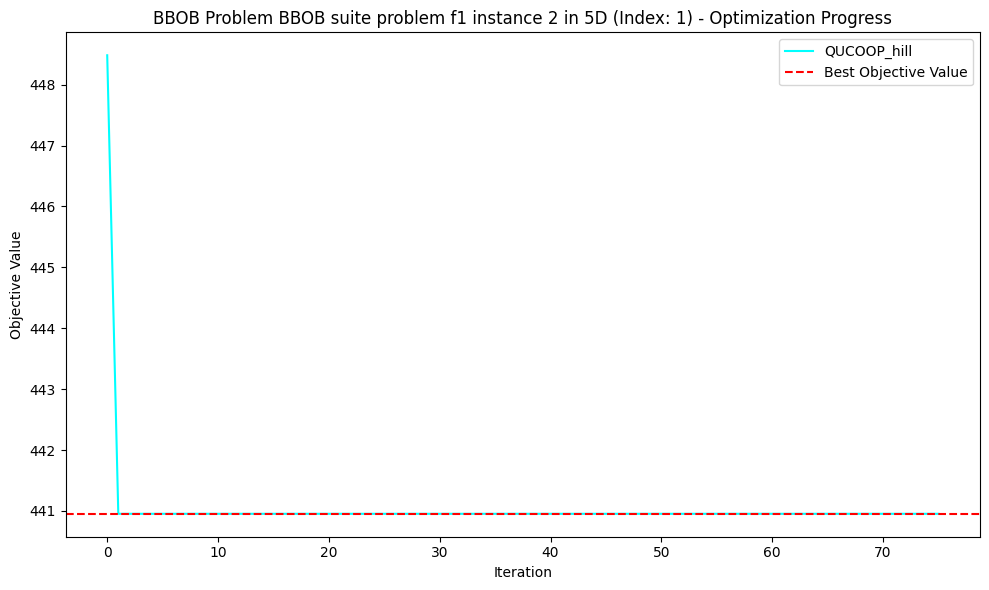

In [2]:
import cocoex  # COCO framework for BBOB problems
from BBOB_QUCOOP2_hill import QUCOOP_hill  # Import your QUCOOP_hill implementation

# ============================================================
# TEST CONFIGURATION
# ============================================================
DIMENSION = 5               # Dimensionality of the BBOB problems
MAX_ITER = 50               # Maximum number of iterations for QUCOOP_hill
SUITE_NAME = "bbob"         # Use the BBOB dataset
SUITE_INSTANCE = "instance:1"
SUITE_OPTIONS = f"dimensions:{DIMENSION}"

# ============================================================
# SETUP BBOB SUITE
# ============================================================
# Load the BBOB problem suite
suite = cocoex.Suite(SUITE_NAME, SUITE_INSTANCE, SUITE_OPTIONS)

# Select a BBOB problem (e.g., Sphere function, problem index 1)
problem_index = 1  # Change this to test other problems
problem = suite.get_problem(problem_index)

print(f"[INFO] Testing BBOB problem: {problem.name} (Index: {problem_index})")

# ============================================================
# SOLVE USING QUCOOP_hill CLASS
# ============================================================
# Initialize the QUCOOP_hill solver
solver = QUCOOP_hill(problem)

# Solve the problem using QUCOOP_hill
history, best_x, best_value = solver.solve(
    total_steps=MAX_ITER,
    q_ratio=0.5,       # Ratio of QUCOOP steps
    hc_iter=3,         # Hill climbing iterations per step
    method="QAOA",     # Use QAOA optimization method
    schedule="alternate"  # Alternate between QUCOOP and hill climbing
)

# ============================================================
# PRINT RESULTS
# ============================================================
print("[TEST] Optimization Results on BBOB Problem")
print(f"Problem Name: {problem.name}")
print(f"Best Solution Found: {best_x}")
print(f"Best Objective Value: {best_value}")
print(f"Objective Value History: {history}")

# ============================================================
# PLOT RESULTS (OPTIONAL)
# ============================================================
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(history, label="QUCOOP_hill", color="cyan")
plt.xlabel("Iteration")
plt.ylabel("Objective Value")
plt.title(f"BBOB Problem {problem.name} (Index: {problem_index}) - Optimization Progress")
plt.axhline(y=min(history), color="red", linestyle="--", label="Best Objective Value")
plt.legend()
plt.tight_layout()
plt.show()